# IND320 Project Work [Part-3]
## Data Quality

Student name: Emre Can Emer

GitHub Repository link: https://github.com/Emriey/IND320_project

StreamLit Share link: https://emriey-ind320-project.streamlit.app/

*Screencast and .pdf files can be found in the GitHub repository.*

## AI Usage
Google Gemini was used for this assignment. I normally prefer to ask small questions if I feel like I'm stuck and look for guidance rather than direct solutions.

*I do not have copilot enabled in VsCode.*

In this assignment however, I did get help from Gemini with coding especially with signal processing. Even with scipy library, I needed help fixing certain errors or plots that weren't making any sense (converting to dB for the spectogram for example, which can be seen at the end).

## Description
This jupyter notebook is used to fullfill the assignment requirements and also as testing grounds for the streamlit app.

**List of fixes as requested by the teacher and suggested by the peer-review from the 2nd assignment:**
- Fixed the pie-chart on the charts page of the streamlit app. The entire page was redesigned and selection options were moved to the sidepanel. The pie chart shows correct amount of import and export values now. The plot on the right side column were also redesigned. It now resamples the data, using the mean of it, which helps with faster loading times and readability. It also responds correctly according to selected year.

- All the plots were changed to dark theme to fit the app better.


**Log of main events:**
- Implemented requested fixes as explained above.

- Acquiring the shape files took a bit searching on my end. The website teacher showed in the lecture was just displaying the data. I had to find another NVE website to actually download it.

- STL and outlier plots look promising. However, I'm not sure about the precipitation outlier function. I feel like its baseline is too low and I couldn't get the parameters right for it.


**Some disclaimers:**
- This project uses 100 randomly generated points instead of the requested 1000. The reason for this is because of API limitations. Even with batching caching, I had problems fetching data for 1000 random points for each 'NO' zone. This also reduces load times significantly in the app. Please let me know if this is a strict requirement and I'll try to fix it.

## Initialization

In [ ]:
# Importing the necessary libraries.
import numpy as np
import pandas as pd
import math
import time
import pickle

import matplotlib.pyplot as plt

import os
import sys
import requests

import geopandas as gpd
from shapely.geometry import Point
from scipy.fft import dct, idct
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL
from scipy.signal import spectrogram, detrend

import openmeteo_requests
import requests_cache
from retry_requests import retry

from dotenv import load_dotenv

# Setting up hadoop PATHs. I have them in windows environment paths too but just in case.
# Spark is spark... you never know.
os.environ["HADOOP_HOME"] = "C:/Hadoop/hadoop-3.3.1" 
os.environ["PYSPARK_HADOOP_VERSION"] = "without"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# I installed dotenv to hide my little secrets. This is one of the neat things I learned from this assignment.
# All the sensitive info are stored in .env and secrets.toml files.
load_dotenv()

True

In [2]:
# 1. Load the shapefile you downloaded from NVE (replace with your actual file path)
# For electricity areas, it will be the file containing your bidding zones (e.g., budomraade.shp)
vaer_gdf = gpd.read_file("shape_files/Nedborfelt_RegineEnhet.shp", encoding="latin1")

In [3]:
vaer_gdf.head()

,objType,vassdragNr,navnLokal,enhAreal,totAreal,hierarki,Q6190lskm2,regineQ,totTilsig,vnrOFelt,navnNedbf,nbfHavNr,navnNbfHav,niva,pktNavnFra,tilPktNavn,uttakDato,ekspType,geometry
0,REGINEenhet,001.21,NaN,0.12,0.0,Haldenvassdraget/Iddefjorden,18.89,0.07,0.0,NaN,KYSTFELT,NaN,KYSTFELT,None,UTLÃP AV ENNINGDALSELVA I IDDEFJORDEN,UTLÃP AV FOLKÃ A I IDDEFJORDEN,2026-11-09,NVEs nedlastningslÃ¸sning,"POLYGON Z ((297636.36 6543422.62 0, 297581.68 ..."
1,REGINEenhet,001.224,NaN,5.96,0.0,Haldenvassdraget/Iddefjorden,14.41,2.71,0.0,NaN,KYSTFELT,NaN,KYSTFELT,None,UTLÃP AV KIRKEBEKKEN I IDDEFJORDEN,UTLÃP AV TISTA (HALDENVASSDRAGET) I IDDEFJORDEN,2026-11-09,NVEs nedlastningslÃ¸sning,"POLYGON Z ((293679.263 6558886.914 0, 293678.2..."
2,REGINEenhet,001.33,NaN,4.19,0.0,Haldenvassdraget/Iddefjorden,14.32,1.89,0.0,NaN,KYSTFELT,NaN,KYSTFELT,None,UTLÃP AV UNNEBERGSBEKKEN I IDDEFJORDEN,KJETANGEN,2026-11-09,NVEs nedlastningslÃ¸sning,"POLYGON Z ((285561.85 6558497.64 0, 285636.23 ..."
3,REGINEenhet,002.114,NaN,21.17,0.0,Glommavassdraget/Hvaler og Singlefjorden,10.79,7.20,0.0,NaN,KYSTFELT,NaN,KYSTFELT,None,UTLÃP AV SKJEBERGBEKKEN I SKJEBERGKILEN,BREVIK,2026-11-09,NVEs nedlastningslÃ¸sning,"POLYGON Z ((280690.8 6569492.91 0, 280732.53 6..."
4,REGINEenhet,002.1161,NaN,8.29,0.0,Glommavassdraget/Hvaler og Singlefjorden,10.81,2.83,0.0,NaN,KYSTFELT,NaN,KYSTFELT,None,MUNKETANGEN,BEVÃYTANGEN,2026-11-09,NVEs nedlastningslÃ¸sning,"POLYGON Z ((275647.03 6563803.94 0, 275633.19 ..."


In [ ]:
# Direct REST API URL for the Budområde layer (Layer 0).
# Taken from the website provided in the assignment page.
url = "https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0/query?where=1%3D1&outFields=*&f=geojson"

# GeoPandas reads the URL and fetches the data.
electricity_gdf = gpd.read_file(url)
electricity_gdf = electricity_gdf.to_crs(epsg=25833)

print(electricity_gdf.head())

   objectid budomr globalid  st_area(shape)  st_perimeter(shape)  \
0         1   NO 1     None    6.052902e+10         1.657761e+06   
1         2   NO 2     None    6.875969e+10         1.256473e+06   
2         3   NO 3     None    1.042199e+11         1.773323e+06   
3         4   NO 4     None    2.032500e+11         3.385499e+06   
4         5   NO 5     None    3.334870e+10         1.106762e+06   

                                            geometry  
0  POLYGON ((337473.63 6970542.97, 337414.99 6970...  
1  POLYGON ((-9833.91 6726499.86, -9861.7 6726719...  
2  POLYGON ((308588.7 7261519.43, 295281.7 726804...  
3  POLYGON ((973920.931 7962739.19, 973255.491 79...  
4  POLYGON ((101466.43 6881318.54, 101382.41 6881...  


In [ ]:
def generate_random_points_in_polygon(polygon, num_points=100):
    """
    This function generates a specified number of random points strictly inside a given polygon.
    """
    # Getting the bounding box (minx, miny, maxx, maxy) of the polygon.
    minx, miny, maxx, maxy = polygon.bounds
    
    points = []
    # Generate points until there is enough valid ones inside the polygon.
    while len(points) < num_points:
        # Generate a batch of random X and Y coordinates within the bounding box.
        needed = num_points - len(points)
        x_coords = np.random.uniform(minx, maxx, needed * 2)
        y_coords = np.random.uniform(miny, maxy, needed * 2)
        
        # Need to check if the generated points are inside the polygons.
        for x, y in zip(x_coords, y_coords):
            p = Point(x, y)
            if polygon.contains(p):
                points.append(p)
                if len(points) == num_points:
                    break
                    
    # Had problems with this. Needed to convert to match the coordinate system.
    return gpd.GeoSeries(points, crs="EPSG:25833")

In [6]:
print(electricity_gdf[electricity_gdf['budomr'] == 'NO 3'][['budomr', 'geometry']])

  budomr                                           geometry
2   NO 3  POLYGON ((308588.7 7261519.43, 295281.7 726804...


In [7]:
print(electricity_gdf['budomr'].unique())

<ArrowStringArray>
['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
Length: 5, dtype: str


In [ ]:
# Decided write a pickle file to store the generated points so won't have to generate them over and over.
# Dictionary to hold points for each zone.
zone_points_dict = {}

for zone_name in ["NO 1", "NO 2", "NO 3", "NO 4", "NO 5"]:
    # Filter your shapefile for the specific zone polygon
    zone_polygon = electricity_gdf[electricity_gdf['budomr'] == zone_name].union_all()
    
    # Generating the 100 points. Had trouble with 1000 points because API limitations.
    points_series = generate_random_points_in_polygon(zone_polygon, num_points=100)
    
    # Convert to avoid coordinate errors.
    points_wgs84 = points_series.to_crs(epsg=4326)
    zone_points_dict[zone_name] = {
        "lats": points_wgs84.y.tolist(),
        "lons": points_wgs84.x.tolist()
    }

# Saving the points.
with open("zone_weather_points.pkl", "wb") as f:
    pickle.dump(zone_points_dict, f)

In [ ]:
# Isolating NO 3 region as requested. Unlike the code above this part only generates points for NO3.
no3_polygon = electricity_gdf[electricity_gdf['budomr'] == 'NO 3'].geometry.union_all()

# Generating 100 points.
random_points_no3 = generate_random_points_in_polygon(no3_polygon, 100)

print(f"Generated {len(random_points_no3)} random points inside the region.")

Generated 100 random points inside the region.


In [ ]:
def download_region_weather_batched(region_name, year, points_geoseries, batch_size=10):
    """
    Downloads hourly ERA5 weather data.
    It is done in small batches because of API limitations.
    This code was taken the open-meteo and adjusted as needed.
    """
    # Caching is important here. No need to fetch the same data again.
    cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
    retry_session = retry(cache_session, retries=5, backoff_factor=0.5)
    openmeteo = openmeteo_requests.Client(session=retry_session)

    # Converting again, as explained above.
    points_wgs84 = points_geoseries.to_crs(epsg=4326)
    lats = points_wgs84.y.tolist()
    lons = points_wgs84.x.tolist()
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    all_locations_data = []

    # Dividing by the batches.
    total_batches = math.ceil(len(lats) / batch_size)
    print(f"Downloading data for '{region_name}' ({year}) across {len(lats)} points in {total_batches} batches...")
    
    for i in range(0, len(lats), batch_size):
        batch_lats = lats[i:i + batch_size]
        batch_lons = lons[i:i + batch_size]
        
        params = {
            "latitude": batch_lats,
            "longitude": batch_lons,
            "start_date": f"{year}-01-01",
            "end_date": f"{year}-12-31",
            "hourly": [
                "temperature_2m", 
                "precipitation", 
                "wind_speed_10m", 
                "surface_pressure"
            ],
            "models": "era5"
        }
        
        print(f"Fetching batch {i // batch_size + 1}/{total_batches}...")
        responses = openmeteo.weather_api(url, params=params)
        
        for j, response in enumerate(responses):
            hourly = response.Hourly()
            if hourly is None:
                continue
                
            global_idx = i + j
            hourly_data = {
                "location_id": global_idx,
                "latitude": response.Latitude(),
                "longitude": response.Longitude(),
                "date": pd.date_range(
                    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=hourly.Interval()),
                    inclusive="left"
                ),
                "temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
                "precipitation": hourly.Variables(1).ValuesAsNumpy(),
                "wind_speed_10m": hourly.Variables(2).ValuesAsNumpy(),
                "surface_pressure": hourly.Variables(3).ValuesAsNumpy()
            }
            
            all_locations_data.append(pd.DataFrame(data=hourly_data))
            
        # Was having trouble with fetching data from the API. This seemed to help.
        time.sleep(1)
            
    master_df = pd.concat(all_locations_data, ignore_index=True)
    return master_df

In [ ]:
# Applying the function for NO3 for 2024
weather_no3_2024 = download_region_weather_batched("NO 3", 2024, random_points_no3, batch_size=10)
print(weather_no3_2024.head())

Fetching batch 1/10...
Fetching batch 2/10...
Fetching batch 3/10...
Fetching batch 4/10...
Fetching batch 5/10...
Fetching batch 6/10...
Fetching batch 7/10...
Fetching batch 8/10...
Fetching batch 9/10...
Fetching batch 10/10...
   location_id  latitude  longitude                      date  temperature_2m  \
0            0      65.0      11.75 2024-01-01 00:00:00+00:00          -4.867   
1            0      65.0      11.75 2024-01-01 01:00:00+00:00          -5.017   
2            0      65.0      11.75 2024-01-01 02:00:00+00:00          -4.717   
3            0      65.0      11.75 2024-01-01 03:00:00+00:00          -4.667   
4            0      65.0      11.75 2024-01-01 04:00:00+00:00          -4.417   

   precipitation  wind_speed_10m  surface_pressure  
0            0.0       33.402489       1011.803894  
1            0.0       33.586281       1011.503235  
2            0.0       33.772911       1011.506714  
3            0.0       33.962330       1011.706482  
4            0.0 

In [ ]:
def analyze_precipitation_outliers(df_weather, cutoff_freq=5, num_stds=3):
    """
    This function analyzes regional precipitation for outliers using DCT high-pass filtering 
    and robust Statistical Process Control (SPC) boundaries.
    """
    # Aggregate to average precipitation across all points over time.
    # Making sure the timestamps are not str.
    df_sorted = df_weather.copy()
    df_sorted['date'] = pd.to_datetime(df_sorted['date'])
    
    # Grouping by time and calculate spatial mean for NO 3.
    time_series = df_sorted.groupby('date')['precipitation'].mean().reset_index()
    time_series = time_series.sort_values('date').set_index('date')
    
    signal = time_series['precipitation'].values
    N = len(signal)
    
    # Applying Discrete Cosine Transform (DCT-II) for High-Pass Filtering.
    coeffs = dct(signal, type=2, norm='ortho')
    
    # Apply high-pass filter to zero out low frequencies.
    coeffs_filtered = coeffs.copy()
    coeffs_filtered[:cutoff_freq] = 0
    
    # Inverse DCT to get the Seasonally Adjusted Variations (SATV).
    satv = idct(coeffs_filtered, type=2, norm='ortho')
    
    # Setting the boundaries.
    median_satv = np.median(satv)
    # Median Absolute Deviation (MAD) scaled for standard deviation.
    mad = np.median(np.abs(satv - median_satv))
    robust_std = 1.4826 * mad 
    
    upper_limit = median_satv + (num_stds * robust_std)
    lower_limit = median_satv - (num_stds * robust_std)
    
    # Identifying outliers based on SATV thresholds above.
    outlier_mask = (satv > upper_limit) | (satv < lower_limit)
    
    # Map back to original precipitation time series for summary/plotting
    time_series['SATV'] = satv
    time_series['Outlier'] = outlier_mask
    
    # Calculate SPC boundaries mapped to the original scale for visualization
    time_series['Upper_SPC'] = time_series['precipitation'] + (upper_limit - satv)
    time_series['Lower_SPC'] = time_series['precipitation'] + (lower_limit - satv)
    
    # Plotting the results.
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Plotting the baseline average precipitation curve.
    ax.plot(time_series.index, time_series['precipitation'], color='blue', alpha=0.6, label='Mean Precipitation')
    
    # Plotting the SPC boundaries.
    ax.plot(time_series.index, time_series['Upper_SPC'], color='orange', linestyle='--', label=f'+{num_stds} Robust SD Limit')
    ax.plot(time_series.index, time_series['Lower_SPC'], color='orange', linestyle='--', label=f'-{num_stds} Robust SD Limit')
    
    # Highlighting the outliers color.
    outliers = time_series[time_series['Outlier']]
    ax.scatter(outliers.index, outliers['precipitation'], color='red', zorder=5, label='Outliers')
    
    ax.set_title("NO 3 Regional Precipitation - SPC Outlier Detection (2024)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation")
    ax.legend()
    plt.tight_layout()
    
    # Summaries at the bottom of the plot to double check.
    summary = {
        "total_observations": N,
        "outlier_count": outlier_mask.sum(),
        "upper_threshold_satv": upper_limit,
        "lower_threshold_satv": lower_limit,
        "outlier_timestamps": outliers.index.tolist()
    }
    
    return fig, summary

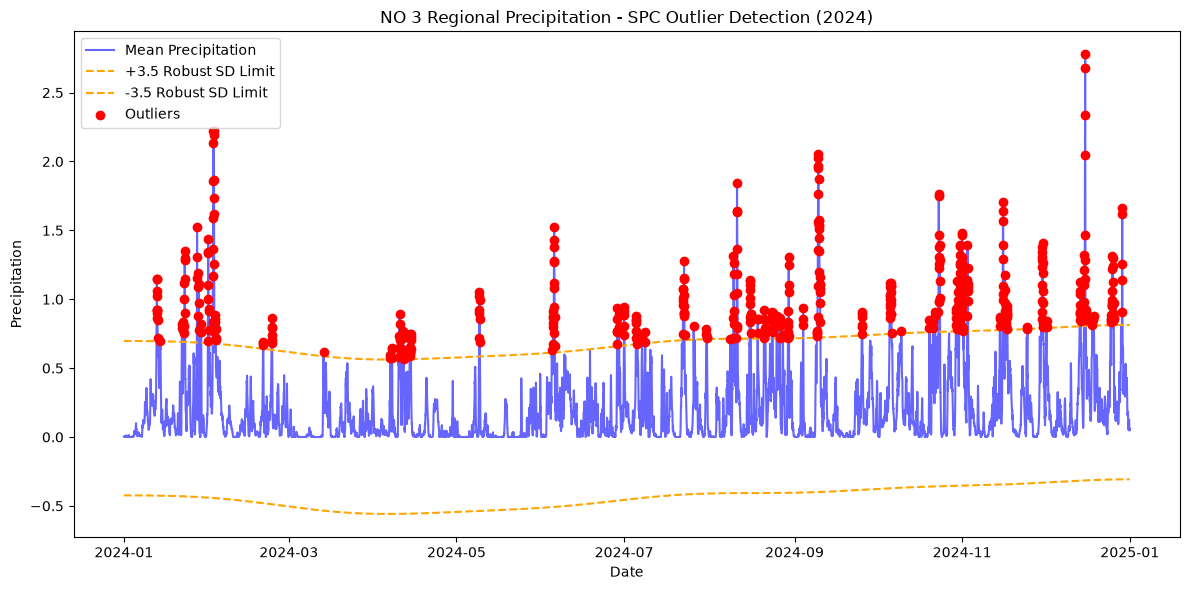

Outlier Analysis Summary: {'total_observations': 8784, 'outlier_count': np.int64(491), 'upper_threshold_satv': np.float32(0.47941804), 'lower_threshold_satv': np.float32(-0.64140344), 'outlier_timestamps': [Timestamp('2024-01-12 21:00:00+0000', tz='UTC'), Timestamp('2024-01-12 22:00:00+0000', tz='UTC'), Timestamp('2024-01-12 23:00:00+0000', tz='UTC'), Timestamp('2024-01-13 00:00:00+0000', tz='UTC'), Timestamp('2024-01-13 01:00:00+0000', tz='UTC'), Timestamp('2024-01-13 02:00:00+0000', tz='UTC'), Timestamp('2024-01-13 03:00:00+0000', tz='UTC'), Timestamp('2024-01-13 04:00:00+0000', tz='UTC'), Timestamp('2024-01-13 05:00:00+0000', tz='UTC'), Timestamp('2024-01-13 06:00:00+0000', tz='UTC'), Timestamp('2024-01-13 07:00:00+0000', tz='UTC'), Timestamp('2024-01-14 04:00:00+0000', tz='UTC'), Timestamp('2024-01-22 02:00:00+0000', tz='UTC'), Timestamp('2024-01-22 03:00:00+0000', tz='UTC'), Timestamp('2024-01-22 15:00:00+0000', tz='UTC'), Timestamp('2024-01-22 16:00:00+0000', tz='UTC'), Timestamp

In [ ]:
# Running the precipitation outlier function.
fig_outliers, summary_outliers = analyze_precipitation_outliers(weather_no3_2024, cutoff_freq=10, num_stds=3.5)
plt.show()
print("Outlier Analysis Summary:", summary_outliers)

In [ ]:
def analyze_temperature_anomalies_lof(df_weather, contamination=0.01):
    """
    This function analyzes regional average temperature for anomalies using the 
    Local Outlier Factor (LOF) method.
    """
    # Aggregate to average temperature across all points over time.
    df_sorted = df_weather.copy()
    df_sorted['date'] = pd.to_datetime(df_sorted['date'])
    
    time_series = df_sorted.groupby('date')['temperature_2m'].mean().reset_index()
    time_series = time_series.sort_values('date').set_index('date')
    
    temperatures = time_series['temperature_2m'].values
    
    # Reshaping input for scikit-learn model and fit LOF.
    X = temperatures.reshape(-1, 1)
    lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
    preds = lof.fit_predict(X)  # -1 indicates an outlier, 1 indicates normal data.
    
    time_series['is_outlier'] = (preds == -1)
    
    # Plotting the anomalies.
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.plot(time_series.index, time_series['temperature_2m'], color='tab:blue', alpha=0.7, label='Mean Temperature')
    
    outliers = time_series[time_series['is_outlier']]
    ax.scatter(outliers.index, outliers['temperature_2m'], color='tab:red', zorder=5, label='LOF Anomalies')
    
    ax.set_title(f"NO 3 Regional Average Temperature - LOF Anomalies (Contamination = {contamination*100}%)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    plt.tight_layout()
    
    # Summaries at the bottom of the plot to double check.
    summary = {
        "total_observations": len(time_series),
        "outlier_count": int(time_series['is_outlier'].sum()),
        "contamination_setting": contamination,
        "anomaly_timestamps": outliers.index.tolist()
    }
    
    return fig, summary

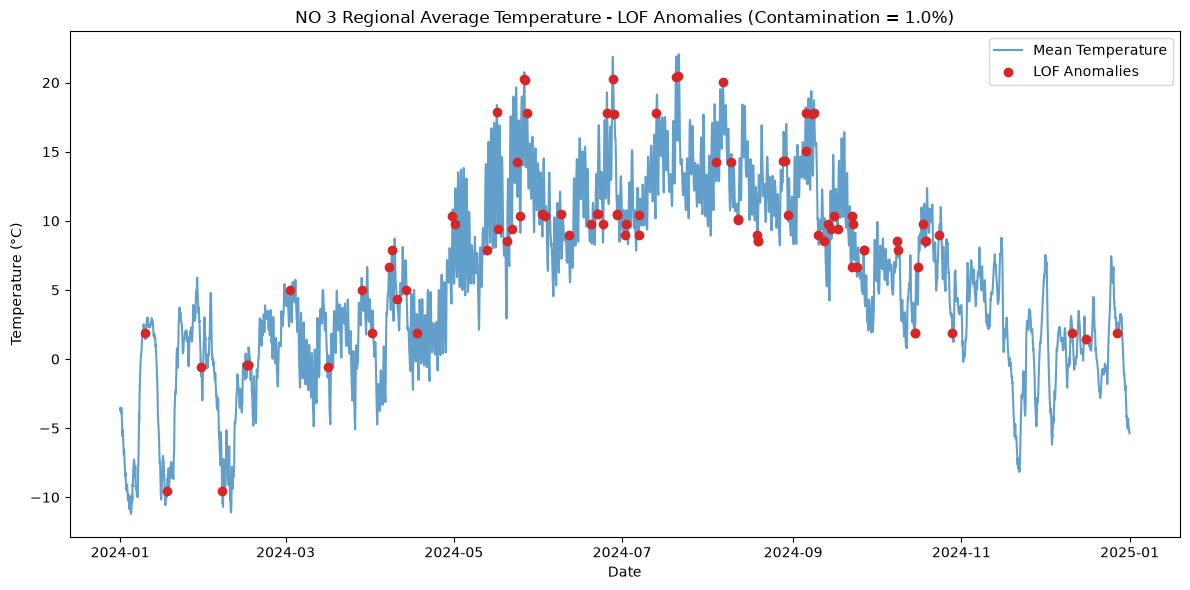

Temperature LOF Summary: {'total_observations': 8784, 'outlier_count': 88, 'contamination_setting': 0.01, 'anomaly_timestamps': [Timestamp('2024-01-09 23:00:00+0000', tz='UTC'), Timestamp('2024-01-17 22:00:00+0000', tz='UTC'), Timestamp('2024-01-30 11:00:00+0000', tz='UTC'), Timestamp('2024-02-07 00:00:00+0000', tz='UTC'), Timestamp('2024-02-16 03:00:00+0000', tz='UTC'), Timestamp('2024-02-16 05:00:00+0000', tz='UTC'), Timestamp('2024-02-16 06:00:00+0000', tz='UTC'), Timestamp('2024-03-02 12:00:00+0000', tz='UTC'), Timestamp('2024-03-16 09:00:00+0000', tz='UTC'), Timestamp('2024-03-28 17:00:00+0000', tz='UTC'), Timestamp('2024-04-01 04:00:00+0000', tz='UTC'), Timestamp('2024-04-07 12:00:00+0000', tz='UTC'), Timestamp('2024-04-08 12:00:00+0000', tz='UTC'), Timestamp('2024-04-10 12:00:00+0000', tz='UTC'), Timestamp('2024-04-13 19:00:00+0000', tz='UTC'), Timestamp('2024-04-17 18:00:00+0000', tz='UTC'), Timestamp('2024-04-30 12:00:00+0000', tz='UTC'), Timestamp('2024-05-01 08:00:00+0000', 

In [ ]:
# Running the LOF anomaly function.
fig_temp_lof, summary_temp_lof = analyze_temperature_anomalies_lof(weather_no3_2024, contamination=0.01)
plt.show()
print("Temperature LOF Summary:", summary_temp_lof)

In [ ]:
# Downloading the magasinstatistikk again.
# The code below is copied from previous assignment.
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
response = requests.get(url)
data = response.json()

reservoir_df = pd.DataFrame(data)

In [21]:
# Renaming the columns.
reservoir_df = reservoir_df.rename(columns={"dato_Id": "date_Id", "omrType": "areaType", "omrnr": "areaNr", "iso_aar": "iso_year",
                                            "iso_uke": "iso_week", "fyllingsgrad": "fill_level", "kapasitet_TWh": "capacity_TWh",
                                            "fylling_TWh": "fill_TWh", "neste_Publiseringsdato": "next_publishdate",
                                            "fyllingsgrad_forrige_uke": "fill_level_lastweek", "endring_fyllingsgrad": "fill_level_change"})

In [22]:
# Converting the "date_Id" column to datetime.
reservoir_df['date_Id'] = pd.to_datetime(reservoir_df['date_Id'])

# Sorting the dataframe according to date.
reservoir_df = reservoir_df.sort_values(by='date_Id').reset_index(drop=True)
display(reservoir_df)

,date_Id,areaType,areaNr,iso_year,iso_week,fill_level,capacity_TWh,fill_TWh,next_publishdate,fill_level_lastweek,fill_level_change
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
2,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
3,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
4,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
...,...,...,...,...,...,...,...,...,...,...,...
14944,2026-11-01,EL,3,2026,44,0.720149,8.920932,6.424399,2026-11-11T13:00:00,0.717935,0.002214
14945,2026-11-01,EL,4,2026,44,0.905202,21.079208,19.080936,2026-11-11T13:00:00,0.904775,0.000427
14946,2026-11-01,VASS,2,2026,44,0.613036,23.237715,14.245566,2026-11-11T13:00:00,0.601080,0.011956
14947,2026-11-01,VASS,3,2026,44,0.850322,28.155403,23.941158,2026-11-11T13:00:00,0.850157,0.000165


In [ ]:
def analyze_reservoir_stl(reservoir_df, area_type='EL', area_nr=3, 
                          seasonal=13, trend=None, robust=True, period=52):
    """
    This function performs STL decomposition on the amount of filling for a specific area.
    """
    # Filtering for NO3.
    # Making sure types and numbers match together.
    df_filtered = reservoir_df[(reservoir_df['areaType'] == area_type) & (reservoir_df['areaNr'].astype(str) == str(area_nr))].copy()
    
    # Sorting according to timestamp.
    df_filtered = df_filtered.sort_values('date_Id').set_index('date_Id')
    
    # Dropping null values just in case.
    fill_series = df_filtered['fill_level'].dropna()
    
    # Fitting STL.
    stl = STL(fill_series, period=period, seasonal=seasonal, trend=trend, robust=robust)
    result = stl.fit()
    
    # Plotting the STL.
    fig = result.plot()
    fig.set_size_inches(10, 8)
    plt.suptitle(f"STL Decomposition for Area {area_type} {area_nr} (Fill Level)", fontsize=14, y=1.02)
    plt.tight_layout()
    
    return fig, result

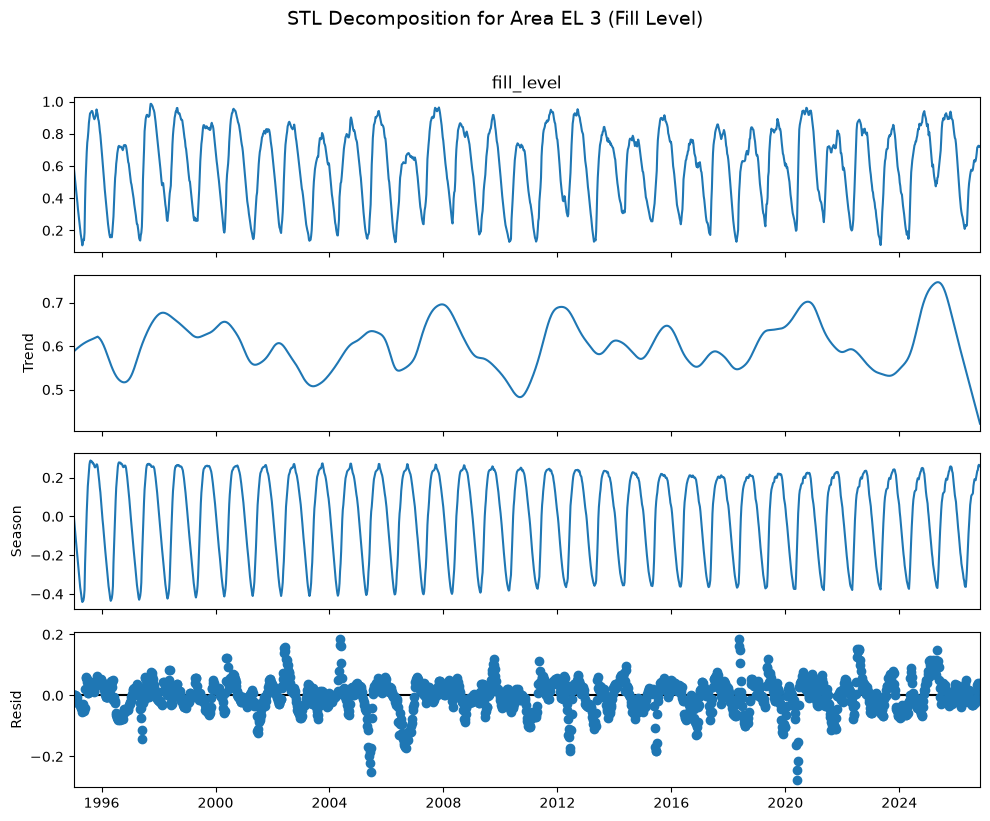

In [ ]:
# Putting everything together.
fig_stl, stl_result = analyze_reservoir_stl(reservoir_df, area_type='EL', area_nr=3, 
                                             seasonal=13, trend=None, robust=True)
plt.show()

In [ ]:
def plot_reservoir_spectrogram(reservoir_df, area_type='EL', area_nr=3, 
                               nperseg=104, noverlap=52, fs=52):
    """
    This function creates and returns a spectrogram plot for the reservoir fill level 
    of a specific area (in this case NO3) using scipy spectrogram function.
    """
    # Filter for the specified area.
    df_filtered = reservoir_df[(reservoir_df['areaType'] == area_type) & (reservoir_df['areaNr'].astype(str) == str(area_nr))].copy()
    
    df_filtered = df_filtered.sort_values('date_Id').set_index('date_Id')
    fill_series = df_filtered['fill_level'].dropna()
    
    # Detrending for focusing purposes.
    signal = detrend(fill_series.values)
    
    # Computes the spectrogram using scipy.
    f, t, Sxx = spectrogram(signal, fs=fs, nperseg=nperseg, noverlap=noverlap)
    
    # Converting the time array (from years) to actual dates for plotting.
    start_date = fill_series.index[0]
    dates = start_date + pd.to_timedelta(t * 365.25, unit='D')
    
    # Plotting the spectogram.
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # It was messy so I looked it up and decided to use dB.
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    im = ax.pcolormesh(dates, f, Sxx_db, shading='gouraud', cmap='viridis')
    
    ax.set_ylabel('Frequency (Cycles / Year)')
    ax.set_xlabel('Time')
    ax.set_title(f'Spectrogram of Reservoir Fill Level - Area {area_type} {area_nr}')
    
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label('Power Spectrum (dB/Hz)')
    plt.tight_layout()
    
    return fig

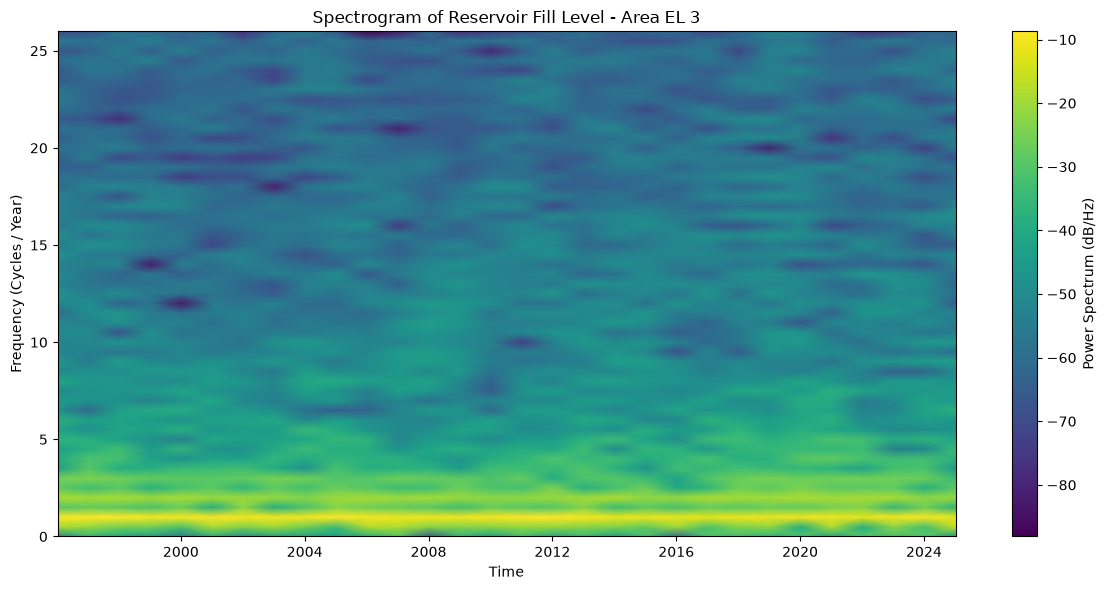

In [ ]:
# Plotting the spectogram.
fig_spectrogram = plot_reservoir_spectrogram(reservoir_df, area_type='EL', area_nr=3, 
                                             nperseg=104, noverlap=52, fs=52)
plt.show()